In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# Load data
df = yf.download('SPY', start="2000-01-01", end="2020-01-01")
df.head()

/tmp/ipykernel_13854/873884209.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('SPY', start="2000-01-01", end="2020-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2000-01-03,91.367516,93.134399,90.385914,93.134399,8164300
2000-01-04,87.794472,90.503693,87.725760,90.169948,8089800
2000-01-05,87.951561,88.913531,86.223941,87.912297,12177900
2000-01-06,86.538071,88.893917,86.538071,87.715994,6227200
2000-01-07,91.563835,91.563835,87.990804,88.147860,8066500


In [ ]:
if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

In [ ]:
price = df['Close']
df['Returns'] = price.pct_change()

In [ ]:
fast = price.rolling(50).mean()
slow = price.rolling(200).mean()

signal = (fast > slow).astype(int)
algo_returns = signal.shift(1) * df['Returns']

In [ ]:
# Compute cumulative return
cumulative_return = (1 + algo_returns).cumprod()
benchmark = (1 + df['Returns']).cumprod()

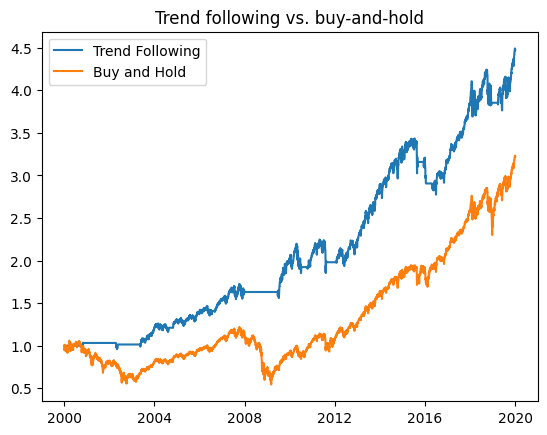

In [ ]:
# Plot cumulative return vs. buy-and-hold
plt.title("Trend following vs. buy-and-hold")
plt.plot(cumulative_return, label='Trend Following')
plt.plot(benchmark, label='Buy and Hold')
plt.legend(loc='upper left');